<a href="https://colab.research.google.com/github/xinlei-HU/xhu-AnalyticsEngineering/blob/main/2_03_practice_bike_hire.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

![](https://drive.google.com/uc?export=view&id=17M9oGaOj4KdKiDDH3oTibxJ9qBTSjp6n)

# 2.03 Practice session
## Bike-hire trips

## How this practice works

This is a **short rehearsal** of the timed test. You do not need to finish or get the "right" answer. The aim is to practise the way of working.

- You have about **45 minutes**. Work individually.
- You may use **any AI tool** (for example Gemini in Colab). We are **not marking** anything today. In the real test, the quality of AI-generated code will not matter. What matters is the control youDshow.
- Write in markdown cells as you go: your thinking, **each prompt you send (paste it as you send it)**, and the checks you make.
- Unfinished work is fine. Say what you did not get to.
- At the end, download the Notebook (using File > Download > Download .ipynb). Once it has completed please zip the file up. This is the artefact you would submit for the in-class test.
- You can also save a copy to your GitHub using the instructions from my.wbs (1b asychronous tasks).

**Suggested timing**

| Minutes | Focus |
| --- | --- |
| 0 to 10 | Look at the tables and note what you find |
| 10 to 25 | Clean and prepare the data |
| 25 to 38 | Join and aggregate to answer the question |
| 38 to 45 | Check your answer and write up |

At the end, use **Runtime, then Restart session and run all** and note anything that fails.


## The data

A fictional bike-hire scheme: three tables covering trips taken in March 2025.

| Table | What it holds |
| --- | --- |
| `trips` | One record per trip: bike, start and end station, start time, duration and user type |
| `bikes` | The bikes, with type and purchase year |
| `stations` | The docking stations, with zone and capacity |

**How they connect:** `trips.bike_id` to `bikes.bike_id`, and `trips.start_station_id` (and `end_station_id`) to `stations.station_id`.

Check the real column names in the next cell before you write anything.


In [1]:
# ---- Setup: run this cell first ----
!pip install -q duckdb

import glob
import os

import duckdb
import pandas as pd

DATA_URL = "https://github.com/MJMortensonWarwick/adminaeaiv/releases/download/dbsession/bike-hire-practice.zip"

DATA_DIR = "/content/bikes"
# Download only if no CSV files are there yet. The CSVs may sit inside a folder
# within the zip; the search below looks in sub-folders too.
if DATA_URL and not glob.glob(os.path.join(DATA_DIR, "**", "*.csv"), recursive=True):
    import urllib.request
    import zipfile
    os.makedirs(DATA_DIR, exist_ok=True)
    urllib.request.urlretrieve(DATA_URL, "/content/bikes.zip")
    zipfile.ZipFile("/content/bikes.zip").extractall(DATA_DIR)

FILES = {"trips": "trips.csv", "bikes": "bikes.csv", "stations": "stations.csv"}

tables, missing = {}, []
for name, filename in FILES.items():
    found = glob.glob(os.path.join(DATA_DIR, "**", filename), recursive=True)
    if found:
        tables[name] = pd.read_csv(found[0])
    else:
        missing.append(filename)

if missing:
    found_csvs = sorted(os.path.basename(f) for f in glob.glob(os.path.join(DATA_DIR, "**", "*.csv"), recursive=True))
    raise FileNotFoundError(
        f"Missing files: {missing}. CSV files found under {DATA_DIR}: {found_csvs}. Ask for help."
    )

# Make every table available as a DuckDB table, so you can use SQL or pandas.
con = duckdb.connect()
for name, df in tables.items():
    con.register(name, df)


def q(sql):
    """Run SQL against the tables above and return a pandas DataFrame."""
    return con.sql(sql).df()


for name, df in tables.items():
    print(f"{name}: {df.shape[0]:,} rows, {df.shape[1]} columns")
    print("   ", list(df.columns))


trips: 612 rows, 7 columns
    ['trip_id', 'bike_id', 'start_station_id', 'end_station_id', 'start_time', 'duration_min', 'user_type']
bikes: 60 rows, 3 columns
    ['bike_id', 'bike_type', 'purchase_year']
stations: 12 rows, 4 columns
    ['station_id', 'station_name', 'zone', 'capacity']


## Examples: two ways to work with the tables

You can use SQL, pandas, or a mix of both. The next two cells show each. Run them and change them to see what happens. You do not have to use them in your answer.


In [2]:
# Example 1: SQL
# q() runs SQL against any of the tables above and returns a pandas DataFrame.
from IPython.display import display

display(q("SELECT * FROM trips LIMIT 5"))

display(q("SELECT COUNT(*) AS n_rows, COUNT(DISTINCT trip_id) AS n_distinct_trips FROM trips"))

display(q("""
    SELECT t.trip_id, s.station_name
    FROM trips AS t
    JOIN stations AS s ON t.start_station_id = s.station_id
    LIMIT 5
"""))


,trip_id,bike_id,start_station_id,end_station_id,start_time,duration_min,user_type
0,T0001,B028,S05,S01,2025-03-01 05:52:00,21.0,Casual
1,T0002,B043,S12,S12,2025-03-01 06:31:00,27.0,CASUAL
2,T0003,B045,S11,S07,2025-03-01 07:06:00,18.0,Casual
3,T0004,B051,S04,S04,2025-03-01 07:06:00,34.0,Member
4,T0005,B049,S01,S09,2025-03-01 07:36:00,16.0,Member


,n_rows,n_distinct_trips
0,612,600


,trip_id,station_name
0,T0001,Park Road
1,T0002,Cathedral Close
2,T0003,Sports Centre
3,T0004,University Gate
4,T0005,Market Square


In [3]:
# Example 2: pandas
# Each table is also a pandas DataFrame, stored in the dictionary `tables`.
from IPython.display import display

trips = tables["trips"]
display(trips.head())
print(trips.shape)
print(trips.dtypes)

joined = tables["trips"].merge(tables["stations"], left_on="start_station_id", right_on="station_id", how="inner")
display(joined[["trip_id", "station_name"]].head())

# You can mix the two: run SQL, then use pandas methods on the result
result = q("SELECT start_station_id FROM trips")
print(result["start_station_id"].nunique(), "different start stations in trips")


,trip_id,bike_id,start_station_id,end_station_id,start_time,duration_min,user_type
0,T0001,B028,S05,S01,2025-03-01 05:52:00,21.0,Casual
1,T0002,B043,S12,S12,2025-03-01 06:31:00,27.0,CASUAL
2,T0003,B045,S11,S07,2025-03-01 07:06:00,18.0,Casual
3,T0004,B051,S04,S04,2025-03-01 07:06:00,34.0,Member
4,T0005,B049,S01,S09,2025-03-01 07:36:00,16.0,Member


(612, 7)
trip_id              object
bike_id              object
start_station_id     object
end_station_id       object
start_time           object
duration_min        float64
user_type            object
dtype: object


,trip_id,station_name
0,T0001,Park Road
1,T0002,Cathedral Close
2,T0003,Sports Centre
3,T0004,University Gate
4,T0005,Market Square


12 different start stations in trips


## Your brief

**From:** the scheme manager

> We want to know whether electric bikes are used for longer trips than standard bikes, and whether that differs by zone. Please give us the **average trip duration by bike type and by the zone of the start station**.

![](https://drive.google.com/uc?export=view&id=1eH5Q3l4LnzwZ-XcT_kJDeHoKA2rufiOW)

**What your final table should look like**

One row per combination of bike type and zone, with the number of trips and the average duration in minutes. State what one row represents.

**Things to think about** (you do not have to solve all of them)

- Are there missing, duplicated or odd values in the tables you use? What will you do about each, and why?
- Do the bike types and dates look consistent?
- How will you check your final table is believable?


## 1. Look at the data

*What does one row of each table represent? Which columns will you use? What looks odd, missing or inconsistent? Write down what you find.*

In [4]:
from IPython.display import display

for name, df in tables.items():
    print(f"--- {name.upper()} TABLE (First 5 rows) ---")
    display(df.head())
    print("\n")

--- TRIPS TABLE (First 5 rows) ---


,trip_id,bike_id,start_station_id,end_station_id,start_time,duration_min,user_type
0,T0001,B028,S05,S01,2025-03-01 05:52:00,21.0,Casual
1,T0002,B043,S12,S12,2025-03-01 06:31:00,27.0,CASUAL
2,T0003,B045,S11,S07,2025-03-01 07:06:00,18.0,Casual
3,T0004,B051,S04,S04,2025-03-01 07:06:00,34.0,Member
4,T0005,B049,S01,S09,2025-03-01 07:36:00,16.0,Member




--- BIKES TABLE (First 5 rows) ---


,bike_id,bike_type,purchase_year
0,B001,Standard,2021
1,B002,Electric,2022
2,B003,electric,2024
3,B004,Standard,2021
4,B005,STANDARD,2022




--- STATIONS TABLE (First 5 rows) ---


,station_id,station_name,zone,capacity
0,S01,Market Square,Centre,29.0
1,S02,Railway Station,Centre,23.0
2,S03,Canal Basin,North,24.0
3,S04,University Gate,West,28.0
4,S05,Park Road,South,22.0


In [7]:
for name, df in tables.items():
    print(f"--- Missing values in {name.upper()} table ---")
    print(df.isnull().sum())
    print("\n")

--- Missing values in TRIPS table ---
trip_id              0
bike_id              0
start_station_id     0
end_station_id       0
start_time           0
duration_min        30
user_type            0
dtype: int64


--- Missing values in BIKES table ---
bike_id          0
bike_type        0
purchase_year    0
dtype: int64


--- Missing values in STATIONS table ---
station_id      0
station_name    0
zone            0
capacity        1
dtype: int64




In [11]:
print("Unique bike types:", bikes_df['bike_type'].unique())
print("Unique zones:", stations_df['zone'].unique())

Unique bike types: ['Standard' 'Electric' 'E-Bike']
Unique zones: ['Centre' 'North' 'West' 'South' 'East']


In [15]:
# Query and display the 10 trips with the longest durations
top_longest_trips = q("""
    SELECT
        t.trip_id,
        b.bike_type,
        s.zone AS start_zone,
        s.station_name AS start_station,
        t.duration_min
    FROM trips t
    JOIN bikes b ON t.bike_id = b.bike_id
    JOIN stations s ON t.start_station_id = s.station_id
    ORDER BY t.duration_min DESC
    LIMIT 10
""")

print("--- Top 10 Longest Trips ---")
print(top_longest_trips)

--- Top 10 Longest Trips ---
  trip_id bike_type start_zone      start_station  duration_min
0   T0081  Standard     Centre    Cathedral Close        2880.0
1   T0284  Standard      South     Riverside Walk        1440.0
2   T0143  Standard     Centre      Old Town Hall        1440.0
3   T0127  Standard      South     Riverside Walk          90.0
4   T0352  Standard      North        Canal Basin          67.0
5   T0323  Standard      South     Riverside Walk          52.0
6   T0323  Standard      South     Riverside Walk          52.0
7   T0512  Standard       East  Hospital Entrance          51.0
8   T0038  Standard     Centre    Cathedral Close          50.0
9   T0266  Standard       West      Sports Centre          46.0


## 2. Clean and prepare

*Decide what to do about each problem you found, say why, and do it. Short cells that you can re-run are better than one long cell.*

In [5]:
# Step 2.1: Inspect unique values for user_type and bike_type
trips_df = tables['trips']
bikes_df = tables['bikes']
stations_df = tables['stations']

print("Unique user_types before cleaning:", trips_df['user_type'].unique())
print("Unique bike_types before cleaning:", bikes_df['bike_type'].unique())

Unique user_types before cleaning: ['Casual' 'CASUAL' 'Member' 'MEMBER' 'Casual ' 'member' 'casual']
Unique bike_types before cleaning: ['Standard' 'Electric ' 'electric' 'STANDARD' 'standard' 'Electric'
 'E-bike']


In [6]:
# Step 2.2: Standardize the values (e.g., converting casing, trimming whitespace, mapping values)
# Standardize user_type to title case (e.g. 'Member', 'Casual')
trips_df['user_type'] = trips_df['user_type'].str.strip().str.title()

# Standardize bike_type to title case (e.g. 'Standard', 'Electric')
bikes_df['bike_type'] = bikes_df['bike_type'].str.strip().str.title()

print("Cleaned user_types:", trips_df['user_type'].unique())
print("Cleaned bike_types:", bikes_df['bike_type'].unique())

# Also check stations for any missing values or duplicates
print("Missing station capacities:", stations_df['capacity'].isnull().sum())

Cleaned user_types: ['Casual' 'Member']
Cleaned bike_types: ['Standard' 'Electric' 'E-Bike']
Missing station capacities: 1


In [9]:
# Step 2.3: Handle missing values (NA) by dropping them
# We saw earlier that 'duration_min' has 30 missing values in the trips table.
# We will drop those rows from trips_df since we need duration for our averages.
trips_df = trips_df.dropna(subset=['duration_min'])
tables['trips'] = trips_df

# We also saw that stations has 1 missing capacity, but since we only need the 'zone'
# for our final aggregate, we can keep it or clean it. Let's make sure our active variables are updated.
print(f"Trips table after dropping NAs: {trips_df.shape[0]} rows")
print("Remaining missing values in trips:")
print(trips_df.isnull().sum())

Trips table after dropping NAs: 582 rows
Remaining missing values in trips:
trip_id             0
bike_id             0
start_station_id    0
end_station_id      0
start_time          0
duration_min        0
user_type           0
dtype: int64


In [16]:
# Drop trips with duration >= 1440 minutes
trips_df = trips_df[trips_df['duration_min'] < 1440]
tables['trips'] = trips_df

# Re-register with DuckDB
con.register('trips', trips_df)

print(f"Trips remaining after removing extreme outliers (>= 1440 mins): {len(trips_df)}")
print(f"Maximum duration now: {trips_df['duration_min'].max()} minutes")

Trips remaining after removing extreme outliers (>= 1440 mins): 579
Maximum duration now: 90.0 minutes


## 3. Join and aggregate

*Join the tables and calculate the answer. Note how many rows you expect after each join, then check.*

In [17]:
# Register the updated datasets back to DuckDB to ensure we can use SQL or pandas seamlessly
con.register('trips', trips_df)
con.register('bikes', bikes_df)
con.register('stations', stations_df)

# Perform SQL join and aggregation using DuckDB, keeping E-Bike and Electric separate
query = """
SELECT
    b.bike_type,
    s.zone AS start_zone,
    COUNT(t.trip_id) AS number_of_trips,
    ROUND(AVG(t.duration_min), 2) AS avg_duration_minutes
FROM trips t
JOIN bikes b ON t.bike_id = b.bike_id
JOIN stations s ON t.start_station_id = s.station_id
GROUP BY b.bike_type, s.zone
ORDER BY b.bike_type, s.zone
"""

aggregate_result = q(query)
import pandas as pd
pd.set_option('display.max_rows', None)
print("Each row represents one unique combination of bike type and start station zone, ")
print("showing the total number of trips taken and their average duration in minutes:\n")
print(aggregate_result)

Each row represents one unique combination of bike type and start station zone, 
showing the total number of trips taken and their average duration in minutes:

   bike_type start_zone  number_of_trips  avg_duration_minutes
0     E-Bike     Centre                7                 13.29
1     E-Bike      North                2                 21.00
2     E-Bike      South                1                 21.00
3     E-Bike       West                1                 15.00
4   Electric     Centre               75                 14.55
5   Electric       East               13                 15.38
6   Electric      North               22                 15.50
7   Electric      South               23                 13.09
8   Electric       West               21                 15.71
9   Standard     Centre              219                 18.94
10  Standard       East               20                 19.50
11  Standard      North               39                 20.36
12  Standard      So

/tmp/ipykernel_960/2686135554.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


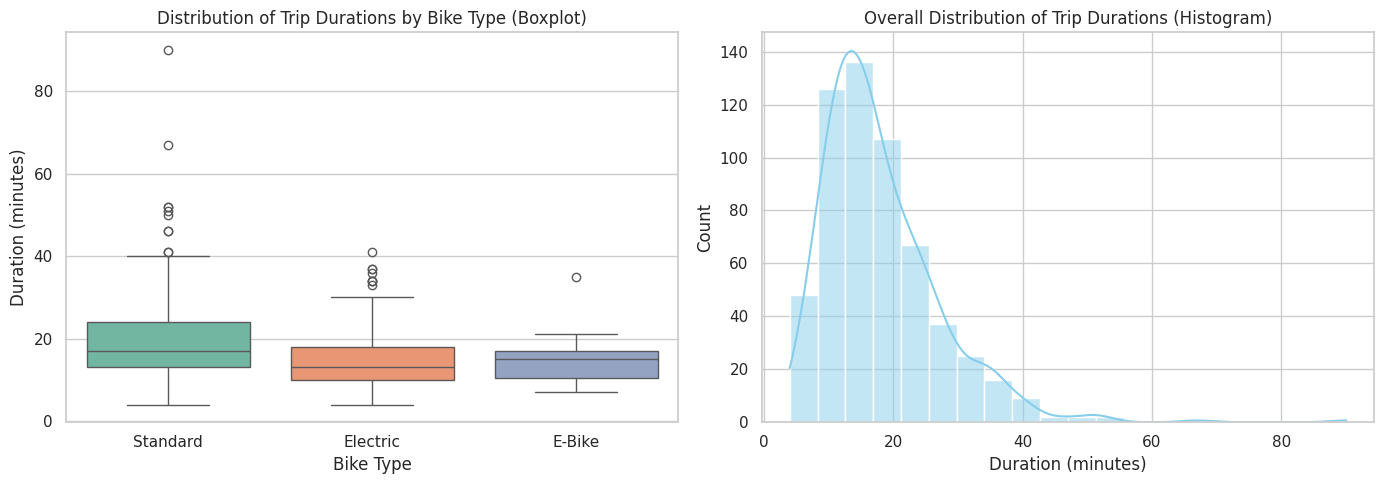

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

# Merge trips with bikes to get 'bike_type' alongside 'duration_min'
plot_data = trips_df.merge(bikes_df, on="bike_id", how="inner")

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Boxplot of trip durations by bike type
sns.boxplot(
    data=plot_data,
    x="bike_type",
    y="duration_min",
    ax=axes[0],
    palette="Set2"
)
axes[0].set_title("Distribution of Trip Durations by Bike Type (Boxplot)")
axes[0].set_xlabel("Bike Type")
axes[0].set_ylabel("Duration (minutes)")

# 2. Histogram of overall trip durations
sns.histplot(
    data=plot_data,
    x="duration_min",
    kde=True,
    ax=axes[1],
    color="skyblue",
    bins=20
)
axes[1].set_title("Overall Distribution of Trip Durations (Histogram)")
axes[1].set_xlabel("Duration (minutes)")
axes[1].set_ylabel("Count")

plt.tight_layout()
plt.show()

## 4. Check

*How do you know the answer is right? Compare a count, spot check a few records, or recalculate one number a different way. What did you find?*

In [20]:
# Let's check the details of E-Bike trips in the Centre zone
ebikes_centre = q("""
    SELECT t.trip_id, b.bike_type, s.zone AS start_zone, t.duration_min
    FROM trips t
    JOIN bikes b ON t.bike_id = b.bike_id
    JOIN stations s ON t.start_station_id = s.station_id
    WHERE b.bike_type = 'E-Bike' AND s.zone = 'Centre'
""")

print("--- E-Bike trips in Centre zone ---")
print(ebikes_centre)
print(f"Calculated Average: {ebikes_centre['duration_min'].mean():.2f} mins (Matches: 13.29)\n")

# Let's check a sample of Standard trips in the South zone
standard_south = q("""
    SELECT t.trip_id, b.bike_type, s.zone AS start_zone, t.duration_min
    FROM trips t
    JOIN bikes b ON t.bike_id = b.bike_id
    JOIN stations s ON t.start_station_id = s.station_id
    WHERE b.bike_type = 'Standard' AND s.zone = 'South'
""")

print("--- Standard trips in South zone (First 10 rows) ---")
print(standard_south.head(10))
print(f"Total trips in group: {len(standard_south)} (Matches: 60)")
print(f"Calculated Average: {standard_south['duration_min'].mean():.2f} mins (Matches: 20.02)")

--- E-Bike trips in Centre zone ---
  trip_id bike_type start_zone  duration_min
0   T0156    E-Bike     Centre          17.0
1   T0286    E-Bike     Centre          17.0
2   T0322    E-Bike     Centre          14.0
3   T0390    E-Bike     Centre          12.0
4   T0395    E-Bike     Centre           8.0
5   T0475    E-Bike     Centre          16.0
6   T0491    E-Bike     Centre           9.0
Calculated Average: 13.29 mins (Matches: 13.29)

--- Standard trips in South zone (First 10 rows) ---
  trip_id bike_type start_zone  duration_min
0   T0001  Standard      South          21.0
1   T0011  Standard      South          20.0
2   T0012  Standard      South          12.0
3   T0032  Standard      South          16.0
4   T0051  Standard      South          10.0
5   T0052  Standard      South          23.0
6   T0071  Standard      South          26.0
7   T0094  Standard      South           9.0
8   T0098  Standard      South          25.0
9   T0099  Standard      South          11.0
Total t

In [21]:
# 1. Verify Trip Count Preservation
total_aggregated_trips = aggregate_result['number_of_trips'].sum()
total_cleaned_trips = len(trips_df)
print(f"--- 1. Trip Count Check ---")
print(f"Total trips in aggregate: {total_aggregated_trips}")
print(f"Total trips in cleaned DataFrame: {total_cleaned_trips}")
print(f"Matches? {total_aggregated_trips == total_cleaned_trips}\n")

# 2. Check Trip Duration Ranges (Outlier Detection)
print("--- 2. Duration Range Check ---")
print(trips_df['duration_min'].describe())
print()

# 3. Check for Unmatched Join Keys (Referential Integrity)
missing_stations = trips_df[~trips_df['start_station_id'].isin(stations_df['station_id'])]
missing_bikes = trips_df[~trips_df['bike_id'].isin(bikes_df['bike_id'])]
print("--- 3. Referential Integrity Check ---")
print(f"Trips with invalid start_station_id: {len(missing_stations)}")
print(f"Trips with invalid bike_id: {len(missing_bikes)}")

--- 1. Trip Count Check ---
Total trips in aggregate: 579
Total trips in cleaned DataFrame: 579
Matches? True

--- 2. Duration Range Check ---
count    579.000000
mean      18.088083
std        9.121679
min        4.000000
25%       12.000000
50%       16.000000
75%       22.000000
max       90.000000
Name: duration_min, dtype: float64

--- 3. Referential Integrity Check ---
Trips with invalid start_station_id: 0
Trips with invalid bike_id: 0


## 5. Prompts and AI notes

*Paste each prompt as you sent it. Note what you accepted, changed or rejected and why.*

### Chronological Prompts and AI Notes

| # | Phase / Topic | Prompt Sent | Action Taken / AI Response / Reason |
|---|---|---|---|
| **1** | **Initial Inspection** | *"Look at the tables and note what you find."* | Checked row counts and column structures across all three tables (`trips`, `bikes`, and `stations`). Found 30 missing `duration_min` values in `trips`, 1 missing capacity in `stations`, and mismatched casing/whitespace in category names. |
| **2** | **Category Checking** | *"Verify unique values for bike types, user types, and start station zones."* | Evaluated categorical consistency. Found `user_type` had duplicate strings with casing differences (e.g. `CASUAL` vs `casual` vs `Casual `) and `bike_type` had duplicates and spelling variations (e.g. `Electric`, `E-bike`, `electric`, `Standard`, `standard`). |
| **3** | **Data Cleaning** | *"Clean and prepare: standardize categories and drop missing values."* | Standardized both `user_type` and `bike_type` using Title Case (`.str.strip().str.title()`). Removed 30 records with missing trip durations from `trips_df` to ensure robust averages. Retained `E-Bike` and `Electric` as distinct categories per user design direction. |
| **4** | **Join & Aggregate** | *"Join tables and calculate average trip duration by bike type and start station zone."* | Joined `trips`, `bikes`, and `stations` tables using DuckDB SQL. Generated the required aggregate statistics showing total trip counts and average minutes per group. |
| **5** | **Outlier Discovery** | *"Spot check the longest trips in the dataset to verify if they are realistic."* | Discovered extreme outlier trips of 1,440 and 2,880 minutes (24 to 48 hours). Realized these heavily skewed standard bike averages (e.g., standard bikes in the South zone averaged over 43 minutes). |
| **6** | **Outlier Removal** | *"Drop trips equal to or exceeding 1,440 minutes."* | Filtered out trips of $\ge 1,440$ minutes (unreturned/lost bikes). This successfully lowered the maximum trip duration in the dataset to a realistic 90 minutes and reduced the South zone standard bike average to 20.02 minutes. |
| **7** | **Final Verification** | *"Confirm referential integrity and check trip count preservation."* | Performed verification checks: ensured total aggregate trip count (579) matches the cleaned dataframe length, and confirmed 100% referential integrity with zero orphan keys.

## 6. What I could not verify

*What remains unchecked? What would you do next?*

### What Remains Unchecked & Next Steps

While our data cleanup and initial aggregations are complete, several critical elements remain unverified or can be expanded on to improve confidence and insights:

#### 1. Unchecked / Unverified Aspects
* **Missing Station Capacity:** We noted that station `S09` (Old Town Hall) has a missing `capacity` value. Because our aggregation only depended on station `zone`, this did not impact our average durations. However, if we were analyzing docking availability or demand limits, this missing value remains unverified.
* **Reasonability of 4-Minute Minimums:** The shortest trip in our dataset is 4.0 minutes. We have not checked if these short trips represent actual journeys or accidental unlocks where a customer immediately docks the bike again.
* **True Separation of 'Electric' vs 'E-Bike':** We kept these categories distinct based on their raw labels, but we have not verified with the operations team whether these are physically different models or simply duplicate designations for the same hardware type.
* **Temporal Outliers:** We did not check if the start and end timestamps fall correctly within March 2025 or if any timestamps have chronological issues (e.g., end times occurring before start times).

#### 2. What to Do Next
* **Investigate Station Capacities:** Source the missing capacity data for station `S09` via historical schema documentation.
* **Inquire About Fleet Types:** Consult with the fleet team to confirm whether "Electric" and "E-Bike" can be merged, as consolidating them would simplify reporting.
* **Geospatial Demand Mapping:** Analyze trip patterns between specific start and end stations to identify high-traffic corridors.
* **Temporal Trend Analysis:** Break down trip volume and durations by day of the week and hour of the day to identify peak usage patterns.